# Robustez de PPO en CarRacing ante un cambio de distribución

Entrenamos PPO (basado en `ppo.py`) en una variante de `CarRacing-v3`. Después cambiamos la forma de la pista y comparamos 5 escenarios:

| Escenario | Modelo |
|-|-|
| 1. Zero-shot | `base`, entrenado en la pista original y evaluado en la nueva |
| 2. Desde cero | `scratch`, entrenado en la pista nueva |
| 3. Fine-tune | `finetune` = `base` reentrenado en la pista nueva |
| 4. LSTM, 3 intentos | `lstm`, entrenado en la pista original. Hace 3 intentos en la misma pista, con el resultado de los intentos anteriores como entrada. Vale el mejor |
| 5. Mezcla | `mix`, entrenado con las dos pistas (50/50) |

```

In [1]:
import base64
import glob
import json
import os
import re
import subprocess
import sys
import time

import cv2
import gymnasium as gym
import imageio.v3 as iio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from matplotlib.collections import PolyCollection

from carracing_env import EPISODE_INFO, make_env
from ppo_carracing import Agent
from ppo_carracing_lstm import Agent as LstmAgent

ROOT = os.path.abspath(".")
MODEL_DIR, TRAIN_DIR, EVAL_DIR, TABLE_DIR, GIF_DIR = (f"{ROOT}/{d}" for d in ["models", "entrenamiento", "evaluacion", "tablas", "gifs"])
for d in [MODEL_DIR, TRAIN_DIR, EVAL_DIR, TABLE_DIR, GIF_DIR]:
    os.makedirs(d, exist_ok=True)

ORIG, NEW, MIX = "CarRacingOriginal-v0", "CarRacingNew-v0", "CarRacingMix-v0"
TRACK_NAME = {ORIG: "original", NEW: "nueva", MIX: "mezcla"}
ATTEMPTS = 3
CHECKPOINTS = 10
# PPO uses whole iterations of 4096 steps, so it runs 244 of them (999,424 steps).
TRAIN_STEPS = {name: 1_000_000 for name in ["base", "scratch", "finetune", "lstm", "mix"]}
TRAIN_TRACK_SEED = {ORIG: 1_000, NEW: 2_000, MIX: 3_000}
EVAL_RUNS = 100
CKPT_EVAL_RUNS = 10
GIF_TRIES = 10

MODELS = list(TRAIN_STEPS)
NUM_EVAL_ENVS = 8
EVAL_SEED, GIF_SEED = 10_000, 20_000
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

START = time.time()


def report(message):
    """Prints the progress and adds it to progreso.log, which can be followed during a run with nbconvert."""
    elapsed = time.strftime("%H:%M:%S", time.gmtime(time.time() - START))
    line = f"[{elapsed}] {message}"
    print(line, flush=True)
    with open(f"{ROOT}/progreso.log", "a") as f:
        f.write(line + "\n")

## Las dos pistas

Mismas seeds en las dos filas.

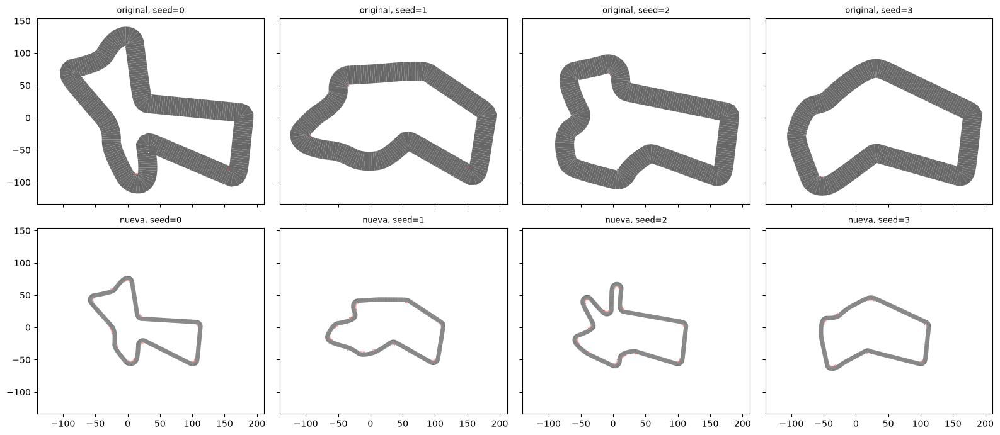

In [2]:
fig, axs = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
for row, env_id in enumerate([ORIG, NEW]):
    env = gym.make(env_id, continuous=False).unwrapped
    for col in range(4):
        env.reset(seed=col)
        polygons = [p for p, _ in env.road_poly]
        colors = [np.array(c) / 255 for _, c in env.road_poly]
        axs[row, col].add_collection(PolyCollection(polygons, facecolors=colors))
        axs[row, col].set_aspect("equal")
        axs[row, col].set_title(f"{TRACK_NAME[env_id]}, seed={col}", fontsize=9)
    env.close()
axs[0, 0].autoscale()
plt.tight_layout()
plt.show()

## Entrenamiento

Si un modelo ya está guardado, no se vuelve a entrenar. Cada modelo guarda 10 checkpoints intermedios.

In [3]:
def train(name, script, env_id, *extra_args):
    model_path = f"{MODEL_DIR}/{name}.pt"
    stage = f"entrenamiento {list(TRAIN_STEPS).index(name) + 1}/{len(TRAIN_STEPS)} ({name})"
    if os.path.exists(model_path):
        report(f"{stage}: ya existe, se saltea")
        return

    cmd = [sys.executable, os.path.abspath(script), "--env-id", env_id, "--total-timesteps", str(TRAIN_STEPS[name]),
           "--track-seed", str(TRAIN_TRACK_SEED[env_id]), "--checkpoints", str(CHECKPOINTS),
           "--exp-name", name, "--save-path", model_path, *extra_args]

    # The script writes tensorboard logs to runs/ in its working directory.
    report(f"{stage}: empieza")
    start = time.time()
    with open(f"{TRAIN_DIR}/{name}.log", "w") as log, \
            subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, cwd=ROOT) as process:
        for line in process.stdout:
            log.write(line)
            if line.startswith("progress: "):
                report(f"{stage}: {line[len('progress: '):].strip()}")
    if process.returncode:
        raise subprocess.CalledProcessError(process.returncode, cmd)
    seconds = time.time() - start

    with open(f"{TRAIN_DIR}/{name}.json", "w") as f:
        json.dump(dict(seconds=seconds, steps=TRAIN_STEPS[name], env_id=env_id), f)
    report(f"{stage}: terminado en {seconds / 60:.1f} min")


train("base", "ppo_carracing.py", ORIG)
train("scratch", "ppo_carracing.py", NEW)
train("finetune", "ppo_carracing.py", NEW, "--init-model", f"{MODEL_DIR}/base.pt")
train("lstm", "ppo_carracing_lstm.py", ORIG, "--attempts", str(ATTEMPTS))
train("mix", "ppo_carracing.py", MIX)

[00:00:01] entrenamiento 1/5 (base): ya existe, se saltea
[00:00:01] entrenamiento 2/5 (scratch): ya existe, se saltea
[00:00:01] entrenamiento 3/5 (finetune): ya existe, se saltea
[00:00:01] entrenamiento 4/5 (lstm): ya existe, se saltea
[00:00:01] entrenamiento 5/5 (mix): ya existe, se saltea


## Evaluación

Cada modelo corre 100 veces en cada pista, en pistas que no vio al entrenar (las mismas para todos). El LSTM hace 3 intentos y vale el mejor.

In [4]:
class Policy:
    """Hides the difference between the feed-forward agent and the LSTM agent."""

    def __init__(self, model_path, is_lstm, envs):
        self.is_lstm = is_lstm
        self.agent = (LstmAgent if is_lstm else Agent)(envs).to(device)
        self.agent.load_state_dict(torch.load(model_path, map_location=device))
        if is_lstm:
            shape = (self.agent.lstm.num_layers, envs.num_envs, self.agent.lstm.hidden_size)
            self.state = (torch.zeros(shape, device=device), torch.zeros(shape, device=device))
            self.done = torch.zeros(envs.num_envs, device=device)

    @torch.no_grad()
    def act(self, obs):
        if self.is_lstm:
            image, feedback = torch.Tensor(obs["image"]).to(device), torch.Tensor(obs["feedback"]).to(device)
            action, _, _, _, self.state = self.agent.get_action_and_value(image, feedback, self.state, self.done)
        else:
            action, _, _, _ = self.agent.get_action_and_value(torch.Tensor(obs).to(device))
        return action.cpu().numpy()

    def observe(self, terminations, truncations):
        if self.is_lstm:
            self.done = torch.Tensor(np.logical_or(terminations, truncations)).to(device)


def evaluate(name, env_id, runs=EVAL_RUNS, model_path=None, seed=EVAL_SEED):
    """Returns one result per run: the return, or the best attempt for the LSTM. Saves all the run data."""
    model_path = model_path or f"{MODEL_DIR}/{name}.pt"
    cache = f"{EVAL_DIR}/{os.path.basename(model_path)[:-len('.pt')]}_eval_{env_id}_{runs}_seed{seed}.npz"
    if os.path.exists(cache):
        return np.load(cache)["best"]

    torch.manual_seed(0)
    is_lstm = name == "lstm"
    envs = gym.vector.AsyncVectorEnv(
        [make_env(env_id, ATTEMPTS if is_lstm else 1, feedback=is_lstm) for _ in range(NUM_EVAL_ENVS)],
        autoreset_mode=gym.vector.AutoresetMode.SAME_STEP,
    )
    policy = Policy(model_path, is_lstm, envs)
    # Env i gets seed + i, like in training, so the same seed gives the same tracks.
    obs, _ = envs.reset(seed=[seed + i for i in range(NUM_EVAL_ENVS)])

    runs_per_env = -(-runs // NUM_EVAL_ENVS)
    results = [[] for _ in range(NUM_EVAL_ENVS)]
    while min(len(r) for r in results) < runs_per_env:
        obs, _, terminations, truncations, infos = envs.step(policy.act(obs))
        policy.observe(terminations, truncations)
        if "final_info" in infos:
            for i in np.flatnonzero(infos["final_info"]["_attempt_returns"]):
                results[i].append({key: infos["final_info"][key][i] for key in EPISODE_INFO})
    envs.close()

    kept = [run for env_runs in results for run in env_runs[:runs_per_env]][:runs]
    data = {key: np.array([run[key] for run in kept]) for key in EPISODE_INFO}
    data["best"] = data["attempt_returns"].max(axis=1)
    np.savez(cache, **data)
    return data["best"]


def ci95(x):
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x))


pairs = [(name, env_id) for name in MODELS for env_id in [ORIG, NEW]]
results = {}
for i, (name, env_id) in enumerate(pairs, 1):
    report(f"evaluación {i}/{len(pairs)}: {name} en la pista {TRACK_NAME[env_id]}")
    results[(name, env_id)] = evaluate(name, env_id)

[00:00:01] evaluación 1/10: base en la pista original
[00:00:01] evaluación 2/10: base en la pista nueva
[00:00:01] evaluación 3/10: scratch en la pista original
[00:00:01] evaluación 4/10: scratch en la pista nueva
[00:00:01] evaluación 5/10: finetune en la pista original
[00:00:01] evaluación 6/10: finetune en la pista nueva
[00:00:01] evaluación 7/10: lstm en la pista original
[00:00:01] evaluación 8/10: lstm en la pista nueva
[00:00:01] evaluación 9/10: mix en la pista original
[00:00:01] evaluación 10/10: mix en la pista nueva


## Transferencia durante el entrenamiento

Retorno medio de cada checkpoint en 10 pistas fijas: las primeras 10 pistas de entrenamiento de cada distribución. Son pistas vistas para `base`, `lstm`, `scratch` y `finetune` en su propia pista, y no vistas para `mix`. El fine-tune arranca en `base` final.

[00:00:01] transferencia 1/5: checkpoints de base
[00:00:01] transferencia 2/5: checkpoints de scratch
[00:00:01] transferencia 3/5: checkpoints de finetune
[00:00:01] transferencia 4/5: checkpoints de lstm
[00:00:01] transferencia 5/5: checkpoints de mix


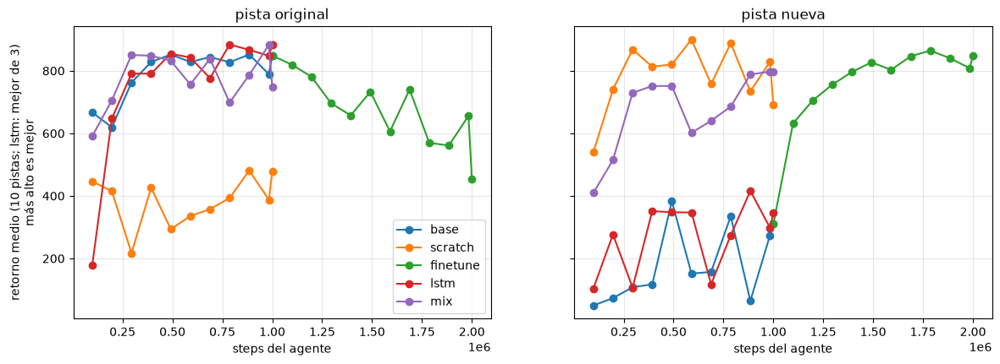

In [5]:
def checkpoints(name):
    # Without the checkpoint files, the cached evaluations still give the steps.
    paths = glob.glob(f"{MODEL_DIR}/{name}_step*.pt") + glob.glob(f"{EVAL_DIR}/{name}_step*_eval_*.npz")
    steps = {int(re.search(r"_step(\d+)[._]", p).group(1)) for p in paths}
    found = {step: f"{MODEL_DIR}/{name}_step{step}.pt" for step in steps}
    found[TRAIN_STEPS[name]] = f"{MODEL_DIR}/{name}.pt"
    if name == "finetune":
        found[0] = f"{MODEL_DIR}/base.pt"
    return found


rows = []
for i, name in enumerate(MODELS, 1):
    report(f"transferencia {i}/{len(MODELS)}: checkpoints de {name}")
    offset = TRAIN_STEPS["base"] if name == "finetune" else 0
    for step, path in sorted(checkpoints(name).items()):
        for env_id in [ORIG, NEW]:
            r = evaluate(name, env_id, CKPT_EVAL_RUNS, path, TRAIN_TRACK_SEED[env_id])
            rows.append(dict(model=name, env_id=env_id, step=step + offset, own_step=step, mean=r.mean(), ci95=ci95(r)))
transfer = pd.DataFrame(rows)
transfer.to_csv(f"{TABLE_DIR}/transfer.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, env_id in zip(axs, [ORIG, NEW]):
    for name in MODELS:
        curve = transfer[(transfer.model == name) & (transfer.env_id == env_id)]
        ax.plot(curve.step, curve["mean"], marker="o", label=name)
    ax.set_title(f"pista {TRACK_NAME[env_id]}")
    ax.set_xlabel("steps del agente")
    ax.grid(alpha=0.3)
axs[0].set_ylabel(f"retorno medio ({CKPT_EVAL_RUNS} pistas; lstm: mejor de 3)\nmás alto es mejor")
axs[0].legend()
plt.show()

## Resumen: rendimiento y costo

Retorno medio ± IC 95%. Las horas del fine-tune incluyen el entrenamiento de `base`.

In [6]:
def train_info(name):
    with open(f"{TRAIN_DIR}/{name}.json") as f:
        return json.load(f)


def train_hours(name):
    hours = train_info(name)["seconds"] / 3600
    return hours + (train_hours("base") if name == "finetune" else 0)


rows = []
for name in MODELS:
    row = {
        "modelo": name,
        "pista de entren.": TRACK_NAME[train_info(name)["env_id"]],
        "horas (acum.)": round(train_hours(name), 2),
        "pistas vistas en entren.": len(np.load(f"{MODEL_DIR}/{name}_episodes.npz")["step"]),
    }
    for env_id in [ORIG, NEW]:
        r = results[(name, env_id)]
        row[f"retorno {TRACK_NAME[env_id]}"] = f"{r.mean():.0f} ± {ci95(r):.0f}"
    rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(f"{TABLE_DIR}/summary.csv", index=False)
summary

,modelo,pista de entren.,horas (acum.),pistas vistas en entren.,retorno original,retorno nueva
0,base,original,1.72,2346,871 ± 24,281 ± 40
1,scratch,nueva,2.17,2570,447 ± 38,857 ± 23
2,finetune,nueva,3.89,2363,608 ± 58,857 ± 28
3,lstm,original,2.17,899,885 ± 16,371 ± 39
4,mix,mezcla,1.91,2439,835 ± 39,817 ± 24


### Retorno en la pista original contra la pista nueva

Barras: IC 95%.

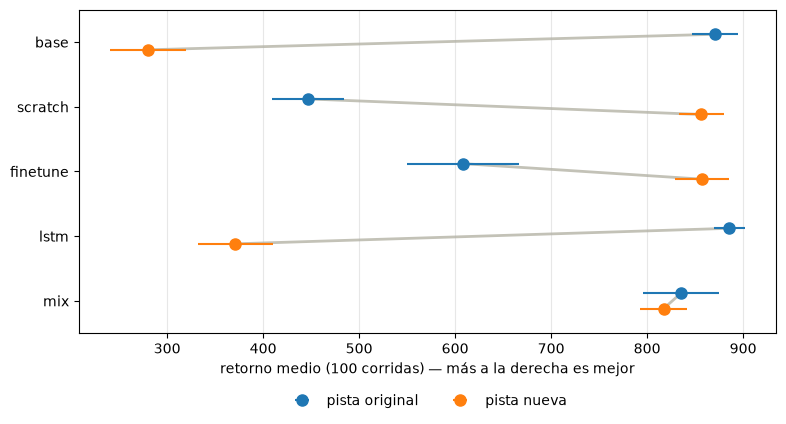

In [7]:
fig, ax = plt.subplots(figsize=(9, 0.6 * len(MODELS) + 1.2))
for y, name in enumerate(MODELS):
    orig, new = results[(name, ORIG)], results[(name, NEW)]
    ax.plot([orig.mean(), new.mean()], [y - 0.12, y + 0.12], color="#c3c2b7", lw=2, zorder=1)
    ax.errorbar(orig.mean(), y - 0.12, xerr=ci95(orig), fmt="o", ms=8, color="tab:blue", zorder=2,
                label="pista original" if y == 0 else None)
    ax.errorbar(new.mean(), y + 0.12, xerr=ci95(new), fmt="o", ms=8, color="tab:orange", zorder=3,
                label="pista nueva" if y == 0 else None)
ax.set_yticks(range(len(MODELS)), MODELS)
ax.set_ylim(len(MODELS) - 0.5, -0.5)
ax.set_xlabel(f"retorno medio ({EVAL_RUNS} corridas) — más a la derecha es mejor")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
ax.grid(axis="x", alpha=0.3)
plt.show()

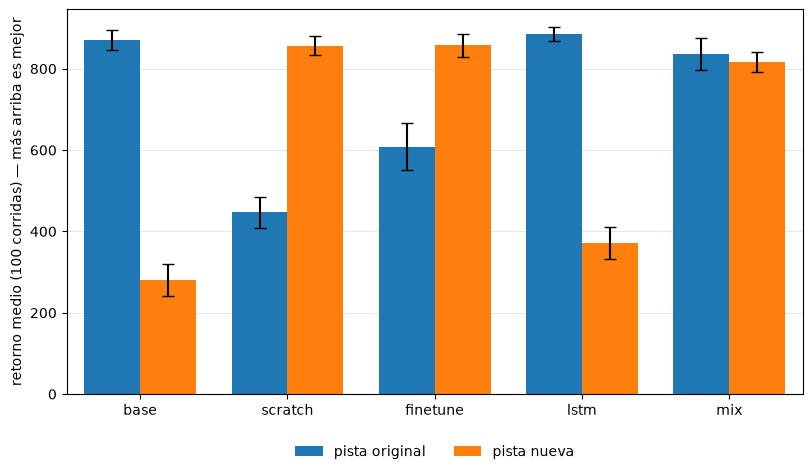

In [8]:
# Same data as bars: models on x, return on y.
fig, ax = plt.subplots(figsize=(1.6 * len(MODELS) + 1.5, 5))
w = 0.38
for x, name in enumerate(MODELS):
    orig, new = results[(name, ORIG)], results[(name, NEW)]
    ax.bar(x - w / 2, orig.mean(), w, yerr=ci95(orig), capsize=4, color="tab:blue",
           label="pista original" if x == 0 else None)
    ax.bar(x + w / 2, new.mean(), w, yerr=ci95(new), capsize=4, color="tab:orange",
           label="pista nueva" if x == 0 else None)
ax.set_xticks(range(len(MODELS)), MODELS)
ax.set_xlim(-0.5, len(MODELS) - 0.5)
ax.set_ylabel(f"retorno medio ({EVAL_RUNS} corridas) — más arriba es mejor")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

### ¿Cuántos steps de fine-tune hacen falta?

Checkpoints del fine-tune en la pista nueva, con las mismas 10 pistas que la transferencia. Ojo: en un checkpoint intermedio el learning rate todavía no bajó del todo.

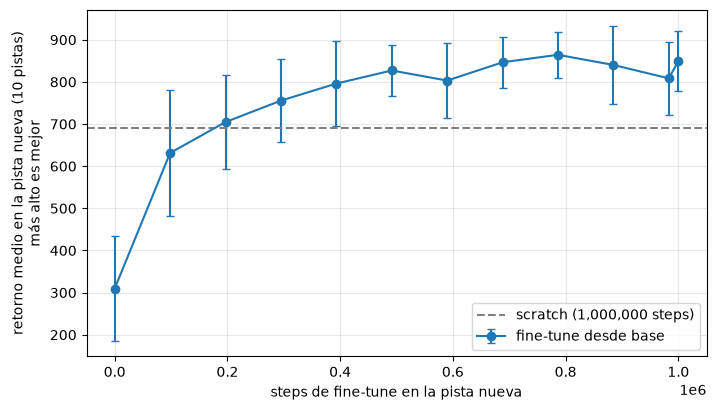

In [9]:
curve = transfer[(transfer.model == "finetune") & (transfer.env_id == NEW)]
scratch_final = transfer[(transfer.model == "scratch") & (transfer.env_id == NEW)].iloc[-1]
plt.figure(figsize=(8, 4.5))
plt.errorbar(curve.own_step, curve["mean"], yerr=curve.ci95, marker="o", capsize=3, label="fine-tune desde base")
plt.axhline(scratch_final["mean"], linestyle="--", color="gray", label=f"scratch ({TRAIN_STEPS['scratch']:,} steps)")
plt.xlabel("steps de fine-tune en la pista nueva")
plt.ylabel(f"retorno medio en la pista nueva ({CKPT_EVAL_RUNS} pistas)\nmás alto es mejor")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## GIFs

Todos los modelos en la misma pista (misma seed en las dos distribuciones). Cada uno tiene 10 intentos y mostramos el mejor. El LSTM corre 10 episodios de 3 intentos y mostramos su mejor intento.

[00:00:03] gif 1/10: base en la pista original
[00:00:03] gif 2/10: scratch en la pista original
[00:00:03] gif 3/10: finetune en la pista original
[00:00:03] gif 4/10: lstm en la pista original
[00:00:03] gif 5/10: mix en la pista original
[00:00:03] gif 6/10: base en la pista nueva
[00:00:03] gif 7/10: scratch en la pista nueva
[00:00:03] gif 8/10: finetune en la pista nueva
[00:00:03] gif 9/10: lstm en la pista nueva
[00:00:03] gif 10/10: mix en la pista nueva



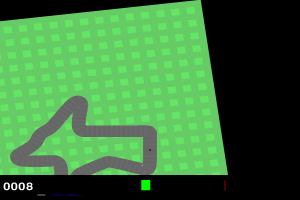
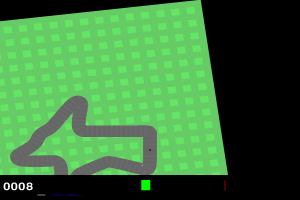
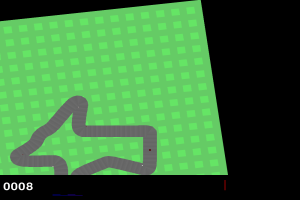
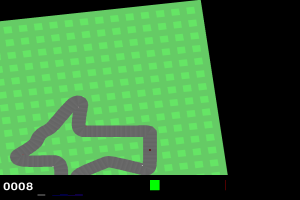
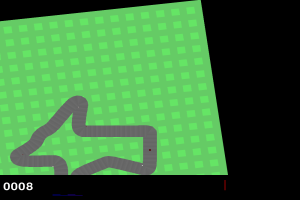
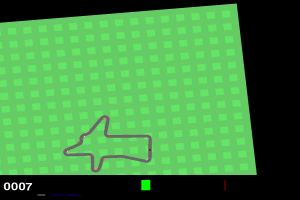
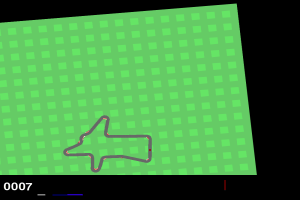
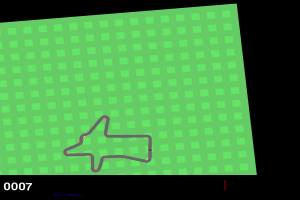
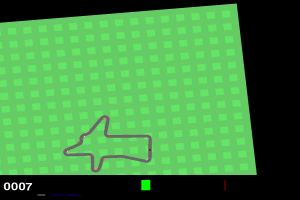
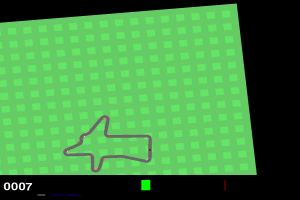

[00:00:03] listo


In [10]:
def record_gif(name, env_id):
    """Saves the best of GIF_TRIES runs on the GIF_SEED track and returns its path and return."""
    path = f"{GIF_DIR}/{name}_{env_id}_seed{GIF_SEED}_{GIF_TRIES}.gif"
    if os.path.exists(path):
        with open(path.replace(".gif", ".json")) as f:
            return path, json.load(f)

    torch.manual_seed(0)
    is_lstm = name == "lstm"
    envs = gym.vector.SyncVectorEnv([make_env(env_id, ATTEMPTS if is_lstm else 1, feedback=is_lstm, render_mode="rgb_array")])
    policy = Policy(f"{MODEL_DIR}/{name}.pt", is_lstm, envs)
    best = None
    for _ in range(GIF_TRIES):
        obs, _ = envs.reset(seed=GIF_SEED)
        frames, done = [], False
        while not done:
            obs, _, terminations, truncations, infos = envs.step(policy.act(obs))
            policy.observe(terminations, truncations)
            frames.append(cv2.resize(envs.call("render")[0], (300, 200)))
            done = terminations[0] or truncations[0]

        # Keeps only the best attempt of the episode (the LSTM runs 3).
        returns, lengths = infos["attempt_returns"][0], infos["attempt_lengths"][0]
        k = returns.argmax()
        if best is None or returns[k] > best[0]:
            start = lengths[:k].sum()
            best = (float(returns[k]), frames[start:start + lengths[k]])
    envs.close()

    result, frames = best
    # One frame is 2 physics steps (40 ms), so every second frame at 80 ms plays at real speed.
    iio.imwrite(path, frames[::2], duration=80, loop=0)
    with open(path.replace(".gif", ".json"), "w") as f:
        json.dump(result, f)
    return path, result


GIFS = [(name, env_id) for env_id in [ORIG, NEW] for name in MODELS]
html = ""
for i, (name, env_id) in enumerate(GIFS, 1):
    report(f"gif {i}/{len(GIFS)}: {name} en la pista {TRACK_NAME[env_id]}")
    path, result = record_gif(name, env_id)
    with open(path, "rb") as f:
        data = base64.b64encode(f.read()).decode()
    html += (f"<figure style='display:inline-block;margin:4px'><img src='data:image/gif;base64,{data}'>"
             f"<figcaption>{name}, pista {TRACK_NAME[env_id]}: {result:.0f}</figcaption></figure>")
display(HTML(html))
report("listo")

## Grilla de distribuciones de pista

Exploramos 16 distribuciones de pista en una grilla de 4 x 4:

- Eje x: ancho de la pista (`TRACK_WIDTH` x 0.5 a x 2.5).
- Eje y: giro máximo (`TRACK_TURN_RATE` 0.1 a 0.4).
- Fijos en todas: radio (`TRACK_RAD` x 0.5) y paso (`TRACK_DETAIL_STEP` x 0.4).

En cada celda entrenamos un modelo desde cero, sin LSTM, durante 500k steps. Todas usan las mismas seeds de entrenamiento. Después evaluamos cada modelo en las 16 distribuciones, con 24 corridas por distribución y las mismas pistas para todos.

Los modelos y las evaluaciones guardados se reusan. Todo queda en:

- `evaluacion/grid_w<i>_t<j>_eval_CarRacingGrid-w<a>-t<b>-v0_24_seed10000.npz`: cada corrida.
- `tablas/grid.npz`: arreglos `[ancho entren., giro entren., ancho eval., giro eval., corrida]`.
- `tablas/grid.csv`: una fila por par (modelo, distribución de evaluación).

In [11]:
from carracing_env import END_REASONS, GRID_TURN_RATES, GRID_WIDTHS, grid_env_id

GRID_STEPS = 500_000
GRID_EVAL_RUNS = 24
GRID_TRAIN_SEED = 5_000
GRID = [(i, j) for i in range(len(GRID_WIDTHS)) for j in range(len(GRID_TURN_RATES))]


def grid_name(i, j):
    return f"grid_w{i}_t{j}"


# train() reads the steps and the training seed from these dicts.
for i, j in GRID:
    TRAIN_STEPS[grid_name(i, j)] = GRID_STEPS
    TRAIN_TRACK_SEED[grid_env_id(i, j)] = GRID_TRAIN_SEED

for i, j in GRID:
    train(grid_name(i, j), "ppo_carracing.py", grid_env_id(i, j))

[00:00:05] entrenamiento 6/21 (grid_w0_t0): ya existe, se saltea
[00:00:05] entrenamiento 7/21 (grid_w0_t1): ya existe, se saltea
[00:00:05] entrenamiento 8/21 (grid_w0_t2): ya existe, se saltea
[00:00:05] entrenamiento 9/21 (grid_w0_t3): ya existe, se saltea
[00:00:05] entrenamiento 10/21 (grid_w1_t0): ya existe, se saltea
[00:00:05] entrenamiento 11/21 (grid_w1_t1): ya existe, se saltea
[00:00:05] entrenamiento 12/21 (grid_w1_t2): ya existe, se saltea
[00:00:05] entrenamiento 13/21 (grid_w1_t3): ya existe, se saltea
[00:00:05] entrenamiento 14/21 (grid_w2_t0): ya existe, se saltea
[00:00:05] entrenamiento 15/21 (grid_w2_t1): ya existe, se saltea
[00:00:05] entrenamiento 16/21 (grid_w2_t2): ya existe, se saltea
[00:00:05] entrenamiento 17/21 (grid_w2_t3): ya existe, se saltea
[00:00:05] entrenamiento 18/21 (grid_w3_t0): ya existe, se saltea
[00:00:05] entrenamiento 19/21 (grid_w3_t1): ya existe, se saltea
[00:00:05] entrenamiento 20/21 (grid_w3_t2): ya existe, se saltea
[00:00:05] ent

In [12]:
grid_runs = {}
for k, ((i, j), (a, b)) in enumerate([(m, e) for m in GRID for e in GRID], 1):
    name, env_id = grid_name(i, j), grid_env_id(a, b)
    report(f"evaluación de la grilla {k}/{len(GRID) ** 2}: {name} en {env_id}")
    evaluate(name, env_id, GRID_EVAL_RUNS)
    # Same file name that evaluate() uses for its cache.
    grid_runs[(i, j, a, b)] = dict(np.load(f"{EVAL_DIR}/{name}_eval_{env_id}_{GRID_EVAL_RUNS}_seed{EVAL_SEED}.npz"))

# Arrays [train width, train turn rate, eval width, eval turn rate, run]. Missing pairs stay NaN.
n_w, n_t = len(GRID_WIDTHS), len(GRID_TURN_RATES)
grid = {key: np.full((n_w, n_t, n_w, n_t, GRID_EVAL_RUNS), np.nan) for key in ["returns", "lengths", "tiles", "ends", "track_seed"]}
for cell, run in grid_runs.items():
    grid["returns"][cell] = run["attempt_returns"][:, 0]
    grid["lengths"][cell] = run["attempt_lengths"][:, 0]
    grid["tiles"][cell] = run["attempt_tiles"][:, 0]
    grid["ends"][cell] = run["attempt_ends"][:, 0]
    grid["track_seed"][cell] = run["track_seed"]
grid["train_seconds"] = np.full((n_w, n_t), np.nan)
for i, j in GRID:
    grid["train_seconds"][i, j] = train_info(grid_name(i, j))["seconds"]
np.savez(f"{TABLE_DIR}/grid.npz", widths=GRID_WIDTHS, turn_rates=GRID_TURN_RATES, end_reasons=END_REASONS, **grid)

rows = []
for (i, j, a, b), run in grid_runs.items():
    r = run["attempt_returns"][:, 0]
    rows.append(dict(train_width=GRID_WIDTHS[i], train_turn_rate=GRID_TURN_RATES[j],
                     eval_width=GRID_WIDTHS[a], eval_turn_rate=GRID_TURN_RATES[b],
                     mean_return=r.mean(), ci95=ci95(r), mean_tiles=run["attempt_tiles"][:, 0].mean(),
                     lap_rate=(run["attempt_ends"][:, 0] == END_REASONS.index("lap")).mean()))
pd.DataFrame(rows).to_csv(f"{TABLE_DIR}/grid.csv", index=False)
report("listo grilla")

[00:00:05] evaluación de la grilla 1/256: grid_w0_t0 en CarRacingGrid-w0-t0-v0
[00:00:05] evaluación de la grilla 2/256: grid_w0_t0 en CarRacingGrid-w0-t1-v0
[00:00:05] evaluación de la grilla 3/256: grid_w0_t0 en CarRacingGrid-w0-t2-v0
[00:00:05] evaluación de la grilla 4/256: grid_w0_t0 en CarRacingGrid-w0-t3-v0
[00:00:05] evaluación de la grilla 5/256: grid_w0_t0 en CarRacingGrid-w1-t0-v0
[00:00:05] evaluación de la grilla 6/256: grid_w0_t0 en CarRacingGrid-w1-t1-v0
[00:00:05] evaluación de la grilla 7/256: grid_w0_t0 en CarRacingGrid-w1-t2-v0
[00:00:05] evaluación de la grilla 8/256: grid_w0_t0 en CarRacingGrid-w1-t3-v0
[00:00:05] evaluación de la grilla 9/256: grid_w0_t0 en CarRacingGrid-w2-t0-v0
[00:00:05] evaluación de la grilla 10/256: grid_w0_t0 en CarRacingGrid-w2-t1-v0
[00:00:05] evaluación de la grilla 11/256: grid_w0_t0 en CarRacingGrid-w2-t2-v0
[00:00:05] evaluación de la grilla 12/256: grid_w0_t0 en CarRacingGrid-w2-t3-v0
[00:00:05] evaluación de la grilla 13/256: grid_w

### Retorno de cada modelo en toda la grilla, relativo al especialista

Cada cuadro es un modelo, ubicado según la distribución en la que entrenó. Adentro de cada cuadro, cada celda es una distribución de evaluación. El borde negro marca la distribución propia del modelo.

Cada celda muestra cuánto más alto (azul) o más bajo (rojo) es el retorno medio que el del especialista: el modelo entrenado en esa distribución. Es (retorno / retorno del especialista) − 1. La celda propia vale 0. Retorno medio de 24 corridas, misma escala de color en todos los cuadros.

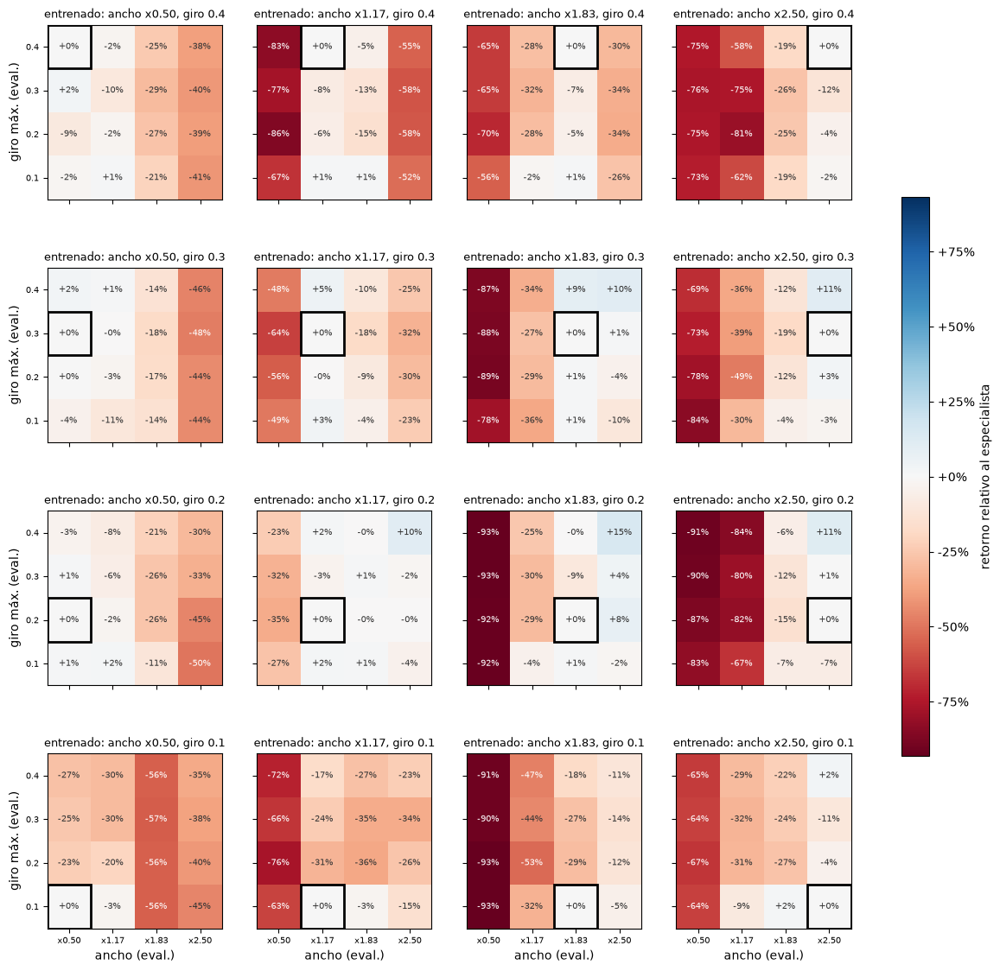

In [13]:
mean_return = np.nanmean(grid["returns"], axis=-1)
vmin, vmax = np.nanmin(mean_return), np.nanmax(mean_return)
w_labels, t_labels = [f"x{w:.2f}" for w in GRID_WIDTHS], [f"{t:.1f}" for t in GRID_TURN_RATES]

# [train width, train turn rate, eval width, eval turn rate]. Each eval cell is compared with the model trained on it.
# abs() keeps the sign right if a model has a negative own return.
own = np.array([[mean_return[i, j, i, j] for j in range(n_t)] for i in range(n_w)])
relative = (mean_return - own[None, None]) / np.abs(own)[None, None]
# Same limit up and down, so that 0 is the neutral color.
rel_lim = np.nanmax(np.abs(relative))

fig, axs = plt.subplots(n_t, n_w, figsize=(15, 14), sharex=True, sharey=True)
for i in range(n_w):
    for j in range(n_t):
        # Higher turn rates go on top.
        ax = axs[n_t - 1 - j, i]
        values = relative[i, j].T
        image = ax.imshow(values, origin="lower", cmap="RdBu", vmin=-rel_lim, vmax=rel_lim)
        for a in range(n_w):
            for b in range(n_t):
                if not np.isnan(values[b, a]):
                    dark = abs(values[b, a]) > rel_lim / 2
                    ax.text(a, b, f"{values[b, a]:+.0%}", ha="center", va="center", fontsize=7, color="white" if dark else "#333333")
        ax.add_patch(plt.Rectangle((i - 0.5, j - 0.5), 1, 1, fill=False, edgecolor="black", lw=2))
        ax.set_title(f"entrenado: ancho {w_labels[i]}, giro {t_labels[j]}", fontsize=9)
        ax.set_xticks(range(n_w), w_labels, fontsize=7)
        ax.set_yticks(range(n_t), t_labels, fontsize=7)
for ax in axs[-1]:
    ax.set_xlabel("ancho (eval.)")
for ax in axs[:, 0]:
    ax.set_ylabel("giro máx. (eval.)")
fig.colorbar(image, ax=axs, shrink=0.6, format=lambda x, _: f"{x:+.0%}", label="retorno relativo al especialista")
plt.show()


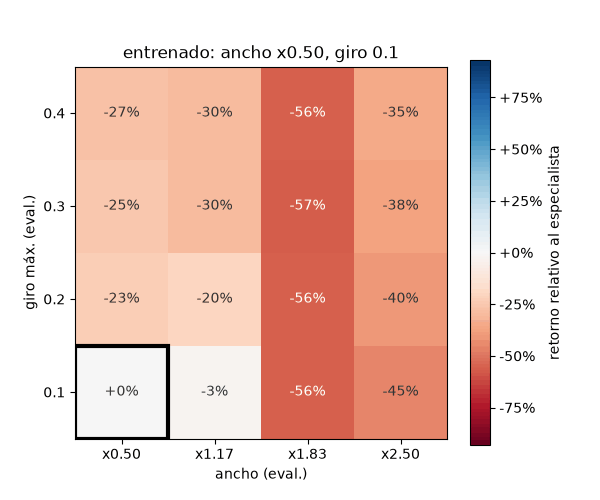

In [14]:
# Animated version: one grid per frame, same color scale in all frames.
frames = []
for i, j in GRID:
    fig, ax = plt.subplots(figsize=(6, 5))
    values = relative[i, j].T
    image = ax.imshow(values, origin="lower", cmap="RdBu", vmin=-rel_lim, vmax=rel_lim)
    for a in range(n_w):
        for b in range(n_t):
            dark = abs(values[b, a]) > rel_lim / 2
            ax.text(a, b, f"{values[b, a]:+.0%}", ha="center", va="center", color="white" if dark else "#333333")
    ax.add_patch(plt.Rectangle((i - 0.5, j - 0.5), 1, 1, fill=False, edgecolor="black", lw=3))
    ax.set_title(f"entrenado: ancho {w_labels[i]}, giro {t_labels[j]}")
    ax.set_xticks(range(n_w), w_labels)
    ax.set_yticks(range(n_t), t_labels)
    ax.set_xlabel("ancho (eval.)")
    ax.set_ylabel("giro máx. (eval.)")
    fig.colorbar(image, ax=ax, format=lambda x, _: f"{x:+.0%}", label="retorno relativo al especialista")
    fig.canvas.draw()
    frames.append(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy())
    plt.close(fig)

# 2 s per model.
path = f"{GIF_DIR}/grid_relativo.gif"
iio.imwrite(path, frames, duration=2000, loop=0)
with open(path, "rb") as f:
    display(HTML(f"<img src='data:image/gif;base64,{base64.b64encode(f.read()).decode()}'>"))

### Resumen por modelo

Izquierda: retorno en su propia distribución. Derecha: retorno relativo al especialista, medio en las otras 15 distribuciones (cuánto generaliza). Más oscuro: mejor.

Las dos escalas van del mínimo al máximo.

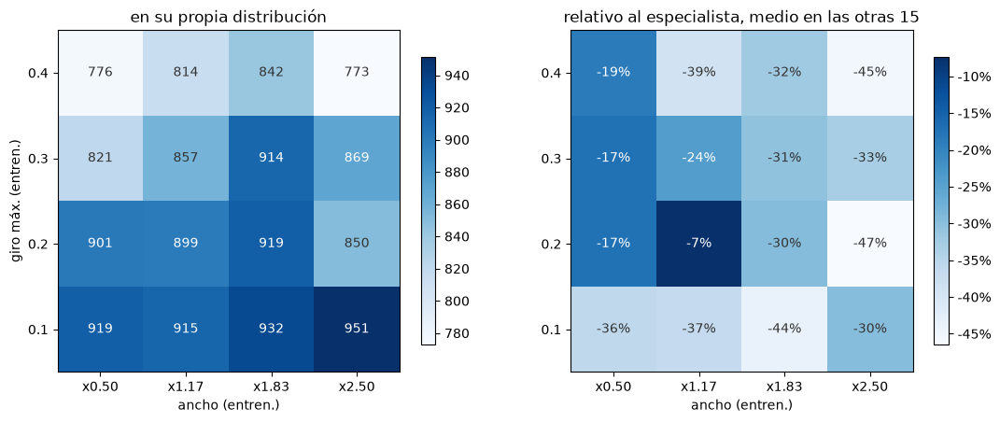

In [15]:
# Mean over the other 15 distributions: the own cell is always 0.
others = relative.copy()
for i, j in GRID:
    others[i, j, i, j] = np.nan
mean_relative = np.nanmean(others, axis=(2, 3))

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, values, title, cmap, lims, fmt in [
    (axs[0], own, "en su propia distribución", "Blues", (own.min(), own.max()), "{:.0f}"),
    (axs[1], mean_relative, "relativo al especialista, medio en las otras 15", "Blues", (mean_relative.min(), mean_relative.max()), "{:+.0%}"),
]:
    image = ax.imshow(values.T, origin="lower", cmap=cmap, vmin=lims[0], vmax=lims[1])
    # Blues is dark at the top of the scale.
    dark = (values - lims[0]) / (lims[1] - lims[0]) > 0.5
    for i in range(n_w):
        for j in range(n_t):
            ax.text(i, j, fmt.format(values[i, j]), ha="center", va="center", color="white" if dark[i, j] else "#333333")
    fig.colorbar(image, ax=ax, shrink=0.8, format=lambda x, _, fmt=fmt: fmt.format(x))
    ax.set_title(title)
    ax.set_xticks(range(n_w), w_labels)
    ax.set_yticks(range(n_t), t_labels)
    ax.set_xlabel("ancho (entren.)")
axs[0].set_ylabel("giro máx. (entren.)")
plt.show()